In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# LOAD
# ==================================================

df = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual_bugfix.csv"
)

# ==================================================
# SUMMARY
# ==================================================

summary = (
    df.groupby(["condition", "num_distractors"])["correct"]
      .agg(["mean", "std", "count"])
      .reset_index()
)

summary["sem"] = (
    summary["std"] / np.sqrt(summary["count"])
)

# ==================================================
# PLOT
# ==================================================

plt.figure(figsize=(8, 5))

for condition in ["disjunctive", "conjunctive"]:

    subset = (
        summary[summary["condition"] == condition]
        .sort_values("num_distractors")
    )

    x = subset["num_distractors"].values
    y = subset["mean"].values
    sem = subset["sem"].values

    plt.plot(
        x,
        y,
        marker="o",
        linewidth=3,
        label=condition.capitalize(),
    )

    plt.fill_between(
        x,
        y - sem,
        y + sem,
        alpha=0.25,
    )
plt.axhline(
    y=0.5,
    color="black",
    linestyle="--",
    linewidth=2,
    alpha=0.8,
    label="Chance (50%)",
)
plt.xlabel("Number of Distractors")
plt.ylabel("Accuracy")
plt.title("Visual Search Accuracy")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

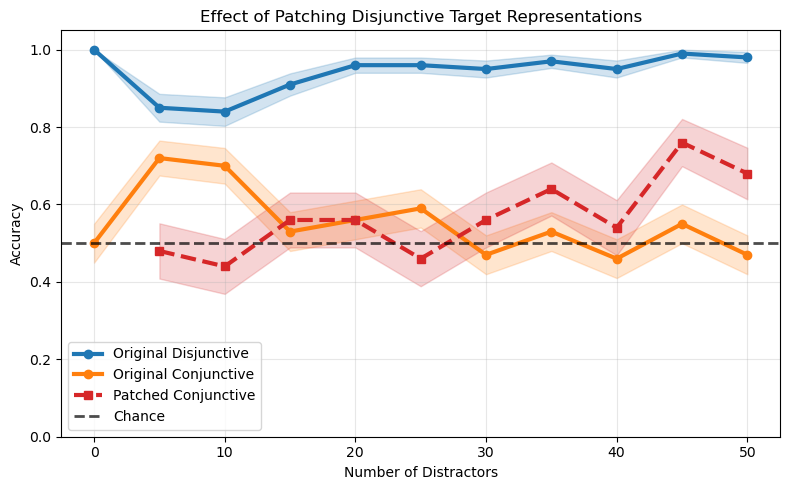

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==================================================
# LOAD
# ==================================================

orig = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/qwen_search_results_counterfactual_bugfix.csv"
)

patched = pd.read_csv(
    "/oscar/data/epavlick/aparasel/Binding-Problem-Brown/Results/conj_disj_bbox_patch.csv"
)

# ==================================================
# ORIGINAL SUMMARY
# ==================================================

orig_summary = (
    orig.groupby(["condition", "num_distractors"])["correct"]
        .agg(["mean", "std", "count"])
        .reset_index()
)

orig_summary["sem"] = (
    orig_summary["std"] /
    np.sqrt(orig_summary["count"])
)

# ==================================================
# PATCHED SUMMARY
# ==================================================

patched_summary = (
    patched.groupby("num_distractors")["correct"]
        .agg(["mean", "std", "count"])
        .reset_index()
)

patched_summary["sem"] = (
    patched_summary["std"] /
    np.sqrt(patched_summary["count"])
)

# ==================================================
# PLOT
# ==================================================

plt.figure(figsize=(8,5))

colors = {
    "disjunctive": "#1f77b4",
    "conjunctive": "#ff7f0e",
    "patched": "#d62728",
}

# -----------------------
# Original curves
# -----------------------

for condition in ["disjunctive", "conjunctive"]:

    sub = (
        orig_summary[
            orig_summary["condition"] == condition
        ]
        .sort_values("num_distractors")
    )

    x = sub["num_distractors"]
    y = sub["mean"]
    sem = sub["sem"]

    plt.plot(
        x,
        y,
        marker="o",
        linewidth=3,
        color=colors[condition],
        label=f"Original {condition.capitalize()}",
    )

    plt.fill_between(
        x,
        y-sem,
        y+sem,
        color=colors[condition],
        alpha=0.20,
    )

# -----------------------
# Patched conjunctive
# -----------------------

x = patched_summary["num_distractors"]
y = patched_summary["mean"]
sem = patched_summary["sem"]

plt.plot(
    x,
    y,
    marker="s",
    linestyle="--",
    linewidth=3,
    color=colors["patched"],
    label="Patched Conjunctive",
)

plt.fill_between(
    x,
    y-sem,
    y+sem,
    color=colors["patched"],
    alpha=0.20,
)

# -----------------------

plt.axhline(
    0.5,
    color="black",
    linestyle="--",
    linewidth=2,
    alpha=0.7,
    label="Chance",
)

plt.xlabel("Number of Distractors")
plt.ylabel("Accuracy")
plt.title("Effect of Patching Disjunctive Target Representations")
plt.ylim(0, 1.05)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()